# Interpretabilidad y auditoría de equidad

**Grupo 5** — Maestría en Inteligencia Artificial Aplicada, UDLA

---

Respalda el reporte `docs/Interpretabilidad_y_etica_Grupo5.pdf`. Dos análisis:

1. **Interpretabilidad** — SHAP sobre los dos ensambles, y por qué el modelo seleccionado no
   necesita una aproximación local como LIME.
2. **Auditoría de equidad** — si el modelo trata por igual a todas las ciudades y distribuidores,
   que es una pregunta que las métricas agregadas no responden.

El segundo análisis es el que aporta evidencia nueva: un MAPE agregado del 4,1 % puede convivir
con desviaciones sistemáticas por territorio, y conviene medirlo antes de que el modelo se use
para decidir asignaciones.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.modules["bottleneck"] = None

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.config import REPORTES, SEMILLA

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": .3,
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
PROC = RAIZ / "data" / "processed"
AZUL, NARANJA, VERDE, GRIS, ROJO = "#2a78d6", "#eb6834", "#1baf7a", "#888780", "#e34948"

d = pd.read_parquet(PROC / "v6_panel_modelo.parquet").sort_values(["marca", "mes"])
per = pd.read_parquet(PROC / "v6_periodos.parquet")
val = per[~per.sin_despacho].copy()
print(f"Panel: {len(d)} filas · periodos con despacho: {len(val):,}")

Panel: 319 filas · periodos con despacho: 258,299


## 1. Interpretabilidad

### Por qué SHAP y no LIME

El modelo seleccionado es **aditivo en escala logarítmica**:

$$\log \mathbb{E}[y] = \log(\text{exposición}) + \log \lambda_{\text{marca}}$$

Su descomposición es exacta y conocida, de modo que una aproximación local como LIME no añadiría
información. SHAP se aplica a los **ensambles**, que sí son cajas negras, y sobre los dos a la vez
para que el resultado no dependa de qué modelo se mire.

El cálculo está en el cuaderno 05; aquí se recupera el resultado guardado.

In [2]:
shap_cmp = pd.read_csv(REPORTES / "shap_dos_ensambles.csv", index_col=0)
shap_cmp.columns = ["XGBoost %", "Random Forest %"]
shap_cmp.head(6)

,XGBoost %,Random Forest %
en_riesgo,70.6,94.2
desp_lag2,16.5,0.9
marca,2.8,0.7
desp_lag1,2.6,0.3
dev_lag1,2.1,0.8
dev_mm3,1.6,0.5


**Los dos ensambles coinciden**: una sola variable concentra la predicción, y Random Forest lo
señala con más fuerza (94,2 %) que XGBoost (70,6 %).

La diferencia tiene explicación. XGBoost usa `colsample_bytree = 0,8`, de modo que en uno de cada
cinco árboles no dispone de `en_riesgo` y recurre a `desp_lag2` —los despachos de hace dos meses,
que son justamente las unidades que ahora vencen—. Es información redundante, no un segundo
factor independiente.

---

## 2. Auditoría de equidad

El modelo asigna a cada unidad la tasa de conversión **de su marca**, sin mirar a dónde fue
despachada. La pregunta es si eso trata por igual a todos los destinos.

El procedimiento compara, para cada grupo, la **tasa real** de permanencia frente a la **tasa que
el modelo le asigna**. Una desviación positiva significa que el modelo *subestima* a ese grupo:
predice menos devoluciones de las que realmente ocurren.

In [3]:
def tasa_marca(mes, W=9, k=300):
    h = d[(d.mes < mes) & (d.mes >= mes - pd.DateOffset(months=W))]
    gl = h.devueltas.sum() / max(h.en_riesgo.sum(), 1)
    a = h.groupby("marca")[["devueltas", "en_riesgo"]].sum()
    return ((a.devueltas + k*gl) / (a.en_riesgo + k)).to_dict(), gl

TE = val[(val.fecha_umbral >= "2026-01-01") & (val.fecha_umbral <= "2026-09-30")].copy()
TE["mes"] = TE.fecha_umbral.dt.to_period("M").dt.to_timestamp()
cierre = TE.mes - pd.Timedelta(days=1)
TE = TE[(TE.inicio_canal <= cierre) & (TE.fin_canal >= cierre)]      # grupo en riesgo

partes = []
for m, b in TE.groupby("mes"):
    t, gl = tasa_marca(m)
    partes.append(pd.Series(b.marca.map(t).fillna(gl).to_numpy(), index=b.index))
TE["tasa_modelo"] = pd.concat(partes).reindex(TE.index)

print(f"Unidades expuestas en los 9 meses de prueba: {len(TE):,}")
print(f"Destinos distintos: {TE.destino.nunique()} · ciudades: {TE.ciudad.nunique()}")
print(f"Sin ciudad registrada: {(TE.ciudad.astype(str) == 'NAN').sum():,}")

Unidades expuestas en los 9 meses de prueba: 10,224
Destinos distintos: 97 · ciudades: 34
Sin ciudad registrada: 1,031


In [4]:
def auditar(col, minimo):
    g = TE.groupby(col).agg(unidades=("imei", "size"), reales=("cumple", "sum"),
                            esperadas=("tasa_modelo", "sum"))
    g = g[g.unidades >= minimo].copy()
    g["tasa_real"] = (g.reales / g.unidades).round(3)
    g["tasa_modelo"] = (g.esperadas / g.unidades).round(3)
    g["desviación"] = (g.tasa_real - g.tasa_modelo).round(3)
    return g.sort_values("desviación")[["unidades", "tasa_real", "tasa_modelo", "desviación"]]

ciu = auditar("ciudad", 150)
print(f"Ciudades con 150+ unidades: {len(ciu)}\n")
pd.concat([ciu.head(3), ciu.tail(4)])

Ciudades con 150+ unidades: 13



,unidades,tasa_real,tasa_modelo,desviación
ciudad,,,,
GUAYAQUIL,1798,0.691,0.715,-0.024
QUITO,2965,0.701,0.721,-0.020
DAULE,181,0.707,0.708,-0.001
PORTOVIEJO,153,0.804,0.705,0.099
LATACUNGA,512,0.812,0.710,0.102
AMBATO,387,0.829,0.712,0.117
MACHALA,384,0.833,0.699,0.134


In [5]:
dis = auditar("destino", 120)
# Los destinos son clientes identificables: se publican con un alias por orden de desviacion,
# sin relacion con el nombre real. DEST_01 es el que el modelo mas sobreestima.
dis.index = pd.Index([f"DEST_{i:02d}" for i in range(1, len(dis) + 1)], name="destino")
print(f"Destinos con 120+ unidades: {len(dis)}")
print(f"  desviación de {dis['desviación'].min():+.3f} a {dis['desviación'].max():+.3f} "
      f"· desv. típica {dis['desviación'].std():.3f}\n")
pd.concat([dis.head(3), dis.tail(3)])

Destinos con 120+ unidades: 37
  desviación de -0.183 a +0.176 · desv. típica 0.085



,unidades,tasa_real,tasa_modelo,desviación
destino,,,,
DEST_01,147,0.531,0.714,-0.183
DEST_02,188,0.601,0.712,-0.111
DEST_03,696,0.625,0.728,-0.103
DEST_35,133,0.872,0.737,0.135
DEST_36,131,0.878,0.714,0.164
DEST_37,194,0.876,0.700,0.176


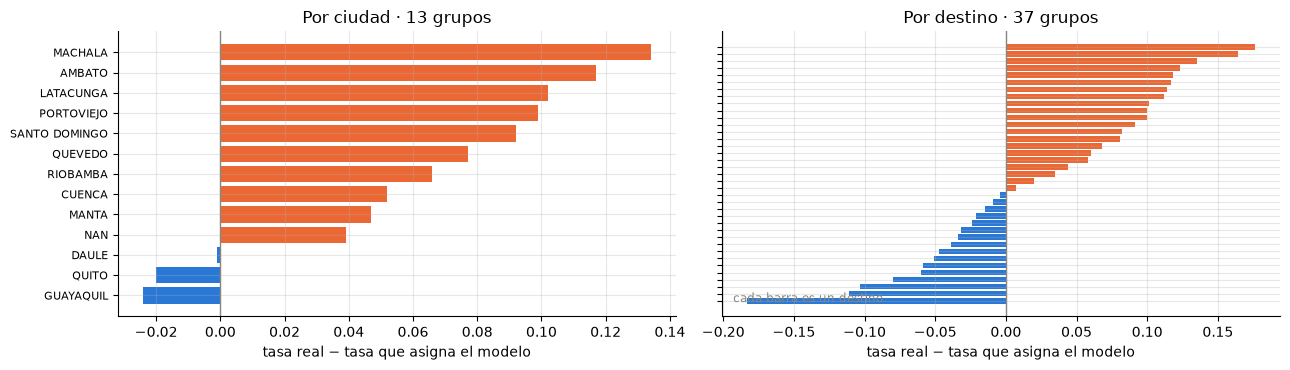

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for i, (g, tit) in enumerate([(ciu, "Por ciudad"), (dis, "Por destino")]):
    col = np.where(g["desviación"] > 0, NARANJA, AZUL)
    ax[i].barh(range(len(g)), g["desviación"], color=col)
    ax[i].axvline(0, color=GRIS, lw=1)
    ax[i].set_yticks(range(len(g)),
                     [t[:26] for t in g.index] if i == 0 else ["" for _ in g.index])
    ax[i].set_xlabel("tasa real − tasa que asigna el modelo")
    ax[i].set_title(f"{tit} · {len(g)} grupos")
    ax[i].tick_params(axis="y", labelsize=8)
ax[1].text(.02, .05, "cada barra es un destino", transform=ax[1].transAxes,
           fontsize=8.5, color=GRIS)
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "f8_equidad.png", dpi=130); plt.show()

### Lo que muestra

**El patrón es sistemático, no ruido.** Las dos ciudades principales —Quito y Guayaquil, que
concentran el grueso del volumen— rotan más rápido y el modelo las sobreestima levemente. Las
ciudades intermedias retienen inventario más tiempo y el modelo las **subestima entre 10 y 13
puntos**.

La causa es mecánica: la tasa de cada marca se estima sobre todo el canal, y como las ciudades
grandes dominan el volumen, esa tasa se parece más a la de ellas que a la del resto.

**Por qué importa antes de desplegar.** Si la predicción se usara para calcular reposición, a las
ciudades intermedias se les asignaría una previsión de devolución menor de la real, y por tanto
una demanda neta mayor de la que corresponde: se les enviaría más producto del que pueden rotar.
El efecto se realimenta.

Nada de esto es visible en el MAPE agregado del 4,1 %.

In [7]:
# ¿Cuánto mejoraría una tasa por ciudad? Cota superior con la tasa observada.
base = np.abs(TE.cumple.astype(float) - TE.tasa_modelo).sum()
porciu = TE.groupby("ciudad").cumple.transform("mean")
alt = np.abs(TE.cumple.astype(float) - porciu).sum()
print(f"Error absoluto agregado a nivel unidad")
print(f"  con tasa por marca          : {base:,.0f}")
print(f"  con tasa observada por ciudad: {alt:,.0f}   ({1-alt/base:.1%} menos)")
print("")
print("Es una cota superior optimista: usa la tasa observada del propio periodo,")
print("no una estimada con datos anteriores. Marca el margen disponible, no la mejora real.")

ciu.to_csv(REPORTES / "equidad_ciudad.csv")
dis.to_csv(REPORTES / "equidad_destino.csv")
print("\nGuardado: equidad_ciudad.csv · equidad_destino.csv · f8_equidad.png")

Error absoluto agregado a nivel unidad
  con tasa por marca          : 4,049
  con tasa observada por ciudad: 3,840   (5.1% menos)

Es una cota superior optimista: usa la tasa observada del propio periodo,
no una estimada con datos anteriores. Marca el margen disponible, no la mejora real.

Guardado: equidad_ciudad.csv · equidad_destino.csv · f8_equidad.png


---

## 3. Conclusiones para el reporte de ética

| Hallazgo | Evidencia |
|---|---|
| Una variable concentra la predicción | 70,6 % en XGBoost y 94,2 % en Random Forest |
| El modelo final no es opaco | seis parámetros, una tasa por marca |
| **Existe sesgo geográfico sistemático** | de −0,024 en Guayaquil a +0,134 en Machala |
| La dispersión por destino es mayor | de −0,183 a +0,176 sobre 37 destinos |
| El agregado lo oculta | el MAPE global es del 4,1 % |
| Hay margen de corrección | añadir el destino como dimensión reduciría el error agregado |

La mitigación que se propone es incorporar el destino —ciudad o tipo de punto de venta— como
dimensión del panel, con el mismo encogimiento jerárquico que ya se aplica a las marcas, de modo
que los destinos con poco volumen hereden la tasa global en vez de seguir su propio ruido.

Mientras eso no se implemente, la recomendación de uso responsable es **reportar el error
desagregado por territorio junto al agregado**, y no emplear la predicción para evaluar
desempeño del canal.